In [1]:
import pandas as pd
import numpy as np


In [2]:
df=pd.read_csv(r"C:\Users\Atharva\Downloads\archive (1)\news.csv")

In [3]:
df.head()

,text,label
0,Gere faults Trump for blurring meaning of 'ref...,1
1,German parties start to find common ground in ...,1
2,Senate Democratic leader says Attorney General...,1
3,"Tennis: Kyrgios fined $10,000 for Shanghai wal...",1
4,Trump Threw Mar-A-Lago Fundraiser For Woman A...,0


In [4]:
df[df['label'] ==1].value_counts().sum()## fake

np.int64(22900)

In [5]:
df[df['label'] ==0].value_counts().sum()## true

np.int64(22857)

In [6]:
df.shape

(45757, 2)

In [7]:
df.isnull().sum()

text     0
label    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

## The Data does not contain any Nan values nor duplicated 

In [9]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [10]:
fake=df[df['label']==1]['text'].values
text=''.join(fake)

In [11]:
from wordcloud import WordCloud

In [12]:
import matplotlib.pyplot as plt

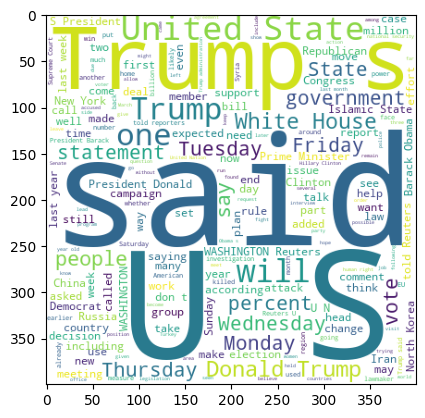

In [13]:
wc=WordCloud(height=400,width=400,background_color='white').generate(text)
plt.imshow(wc)

In [14]:
real=df[df['label'] == 0]['text'].values
text=''.join(real)

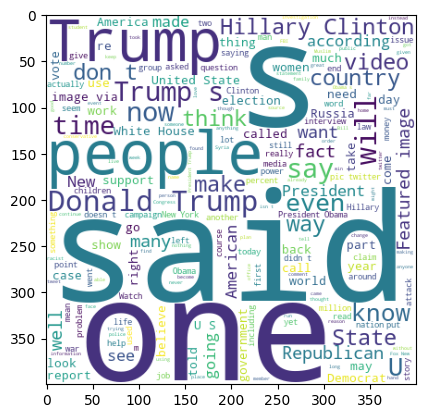

In [15]:
wc1=WordCloud(height=400,width=400,background_color='white').generate(text)
plt.imshow(wc1)

In [16]:
from nltk.tokenize import word_tokenize

In [17]:
lemmatizer=WordNetLemmatizer()
stop_words=set(stopwords.words('english'))

In [18]:
import re
def clean_text(text):
    text = str(text).lower()
    # remove urls
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # remove mentions and hashtags (keeps hashtag words if you prefer remove the # only use: text = re.sub(r'#','',text))
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#\w+', '', text)
    # keep only letters and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)
    # collapse multiple spaces
    text = re.sub(r'\s+', ' ', text).strip()
    # tokenize
    tokens = word_tokenize(text)
    # remove stopwords and lemmatize
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return ' '.join(tokens)

In [19]:
df['text'] = df['text'].apply(clean_text)

In [20]:
df.head()

,text,label
0,gere fault trump blurring meaning refugee terr...,1
1,german party start find common ground coalitio...,1
2,senate democratic leader say attorney general ...,1
3,tennis kyrgios fined shanghai walk tennis chin...,1
4,trump threw mar lago fundraiser woman center b...,0


## Now the text is Cleaned -> seperating X and y 

In [21]:
X=df['text']
y=df['label']

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [24]:
X_train.shape

(36605,)

In [25]:
y_train.shape

(36605,)

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [27]:
tfidf=TfidfVectorizer()
X_train=tfidf.fit_transform(X_train)
X_test=tfidf.transform(X_test)

In [28]:
from sklearn.metrics import classification_report,roc_auc_score

In [29]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Test-accuracy->",model.score(X_test,y_test))
print("Roc-Auc-Score->",roc_auc_score(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4572
           1       0.97      0.97      0.97      4580

    accuracy                           0.97      9152
   macro avg       0.97      0.97      0.97      9152
weighted avg       0.97      0.97      0.97      9152

Test-accuracy-> 0.9717001748251748
Roc-Auc-Score-> 0.9717017769067077


In [30]:
from sklearn.metrics import classification_report,roc_auc_score

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier 
from sklearn.naive_bayes import BernoulliNB,GaussianNB,MultinomialNB
from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from sklearn.ensemble import VotingClassifier

In [32]:
model=DecisionTreeClassifier()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      4572
           1       0.98      0.98      0.98      4580

    accuracy                           0.98      9152
   macro avg       0.98      0.98      0.98      9152
weighted avg       0.98      0.98      0.98      9152



In [33]:
print("Train-Accuracy->",model.score(X_train,y_train))
print("Test-accuracy->",model.score(X_test,y_test))

Train-Accuracy-> 0.9999726813276875
Test-accuracy-> 0.9795673076923077


In [34]:
model=RandomForestClassifier()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Train-Accuracy->",model.score(X_train,y_train))
print("Test-accuracy->",model.score(X_test,y_test))

              precision    recall  f1-score   support

           0       0.96      0.97      0.97      4572
           1       0.97      0.96      0.97      4580

    accuracy                           0.97      9152
   macro avg       0.97      0.97      0.97      9152
weighted avg       0.97      0.97      0.97      9152

Train-Accuracy-> 0.9999726813276875
Test-accuracy-> 0.9674388111888111


In [35]:
print(roc_auc_score(y_test,y_pred))

0.9674447080577809


In [36]:
model=XGBClassifier()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Train-Accuracy->",model.score(X_train,y_train))
print("Test-accuracy->",model.score(X_test,y_test))
print("Roc-Auc-Score->",roc_auc_score(y_test,y_pred))

KeyboardInterrupt: 

In [ ]:
model=BernoulliNB()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Train-Accuracy->",model.score(X_train,y_train))
print("Test-accuracy->",model.score(X_test,y_test))
print("Roc-Auc-Score->",roc_auc_score(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.94      0.90      0.92      4572
           1       0.90      0.94      0.92      4580

    accuracy                           0.92      9152
   macro avg       0.92      0.92      0.92      9152
weighted avg       0.92      0.92      0.92      9152

Train-Accuracy-> 0.9325228793880618
Test-accuracy-> 0.9207823426573427
Roc-Auc-Score-> 0.9207623201030003


In [ ]:
model=MultinomialNB()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Train-Accuracy->",model.score(X_train,y_train))
print("Test-accuracy->",model.score(X_test,y_test))
print("Roc-Auc-Score->",roc_auc_score(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.92      0.92      0.92      4572
           1       0.92      0.92      0.92      4580

    accuracy                           0.92      9152
   macro avg       0.92      0.92      0.92      9152
weighted avg       0.92      0.92      0.92      9152

Train-Accuracy-> 0.9299002868460593
Test-accuracy-> 0.9195804195804196
Roc-Auc-Score-> 0.9195824593978155


In [ ]:
model=AdaBoostClassifier()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Train-Accuracy->",model.score(X_train,y_train))
print("Test-accuracy->",model.score(X_test,y_test))
print("Roc-Auc-Score->",roc_auc_score(y_test,y_pred))


              precision    recall  f1-score   support

           0       0.96      0.99      0.98      4572
           1       0.99      0.96      0.98      4580

    accuracy                           0.98      9152
   macro avg       0.98      0.98      0.98      9152
weighted avg       0.98      0.98      0.98      9152

Train-Accuracy-> 0.9757137003141647
Test-accuracy-> 0.9759615384615384
Roc-Auc-Score-> 0.9759748917848151


In [ ]:
import pickle
pickle.dump(df,open('cleaneddf.pkl','wb'))
pickle.dump(model,open('ada.pkl','wb'))

In [38]:
from sklearn.metrics import r2_score

In [39]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(classification_report(y_test,y_pred))
print("Test-accuracy->",model.score(X_test,y_test))
print("Roc-Auc-Score->",roc_auc_score(y_test,y_pred))
print(r2_score(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.97      0.97      0.97      4572
           1       0.97      0.97      0.97      4580

    accuracy                           0.97      9152
   macro avg       0.97      0.97      0.97      9152
weighted avg       0.97      0.97      0.97      9152

Test-accuracy-> 0.9717001748251748
Roc-Auc-Score-> 0.9717017769067077
0.8868006128054954


In [ ]:
pickle.dump(model,open('logistic.pkl','wb'))

In [ ]:
import pickle
df=pickle.load(open('cleaneddf.pkl','rb'))

In [ ]:
df.head()

,text,label
0,gere fault trump blurring meaning refugee terr...,1
1,german party start find common ground coalitio...,1
2,senate democratic leader say attorney general ...,1
3,tennis kyrgios fined shanghai walk tennis chin...,1
4,trump threw mar lago fundraiser woman center b...,0


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia=SentimentIntensityAnalyzer()

def get_sentiment(text):
    scores=sia.polarity_scores(text)
    compound=scores['compound']

    if compound >= 0.05:
        label='Positive'
    elif compound <= -0.05:
        label='Negative'
    else:
        label ='Neutral'
    return label,compound



In [ ]:
import pandas as pd
import numpy as np

df[['sentiment_label','sentiment_score']]=(df['text'].apply(get_sentiment).apply(pd.Series))

In [ ]:
df.groupby('label')['sentiment_score'].mean()

label
0   -0.059000
1    0.097869
Name: sentiment_score, dtype: float64

In [ ]:
df.head()

,text,label,sentiment_label,sentiment_score
0,gere fault trump blurring meaning refugee terr...,1,Negative,-0.9652
1,german party start find common ground coalitio...,1,Positive,0.9711
2,senate democratic leader say attorney general ...,1,Positive,0.4588
3,tennis kyrgios fined shanghai walk tennis chin...,1,Negative,-0.9761
4,trump threw mar lago fundraiser woman center b...,0,Positive,0.5423


In [ ]:
model=pickle.load(open('logistic.pkl','rb'))

In [ ]:
import shap
explainer=shap.LinearExplainer(model,X_train)
sample_idx=50
X_sample=X_test[sample_idx:sample_idx+1]
shap_values=explainer.shap_values(X_sample)
feature_names=tfidf.get_feature_names_out()

shap_df=pd.DataFrame({
    'word':feature_names,
    'shap_value':shap_values[0]
}).sort_values('shap_value',key=abs,ascending=False).head(15)
print(shap_df) 

c:\Users\Atharva\cs corner\ML_PROJECTS\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 36605 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=36605 when initializing the masker.


                                                     word  shap_value
63960   <bound method CountVectorizer.get_feature_name...    0.641639
73960   <bound method CountVectorizer.get_feature_name...    0.533023
87944   <bound method CountVectorizer.get_feature_name...    0.198979
85258   <bound method CountVectorizer.get_feature_name...    0.148778
1520    <bound method CountVectorizer.get_feature_name...    0.147286
110329  <bound method CountVectorizer.get_feature_name...    0.129491
98243   <bound method CountVectorizer.get_feature_name...    0.118572
108350  <bound method CountVectorizer.get_feature_name...    0.111263
71425   <bound method CountVectorizer.get_feature_name...    0.107821
53882   <bound method CountVectorizer.get_feature_name...    0.095011
109867  <bound method CountVectorizer.get_feature_name...   -0.089099
43967   <bound method CountVectorizer.get_feature_name...    0.086512
14772   <bound method CountVectorizer.get_feature_name...    0.085495
101350  <bound metho

In [ ]:
import shap
expaliner=shap.LinearExplainer(model=model,X_train)
sample_idx=50
X_sample=X_test[sample_idx:sample_idx+1]
sahp_values=expaliner.shap_values(X_sample)
feature_names=tfidf.get_feature_names_out()

shapdf=pd.DataFrame({
    'features':feature_names,
    'shap_values':sahp_values[0]
}).sort_values('shap_values',key=abs,ascending=False)
print(shapdf)

In [ ]:
# category detection
category_keywords={
    'politics':['election','president','government','congress','minister'],
    'sports':['match','tournament','player','championship','league','tennis','football'],
    'business':['market','stock','economy','company','trade','finance'],
    'entertainment':['movie','celebrity','music','film','actor','show'],
    'health':['hospital','disease','vaccine','doctor','health','covid'],
    'world':['country','nation','international','war','conflict']
}

def detct_category(text):
    text_lower=text.lower()
    score={cat:sum(text_lower.count(word) for word in words)
           for cat,words in category_keywords.items()}
    best_cat=max(score,key=score.get)
    return best_cat if score[best_cat] > 0 else 'general'



In [ ]:
df['category']=df['text'].apply(detct_category)

In [ ]:
df['category'].value_counts()

category
politics         22450
world            12631
entertainment     2870
general           2794
business          2571
health            1626
sports             815
Name: count, dtype: int64

In [ ]:
df

,text,label,sentiment_label,sentiment_score,category
0,gere fault trump blurring meaning refugee terr...,1,Negative,-0.9652,entertainment
1,german party start find common ground coalitio...,1,Positive,0.9711,politics
2,senate democratic leader say attorney general ...,1,Positive,0.4588,politics
3,tennis kyrgios fined shanghai walk tennis chin...,1,Negative,-0.9761,sports
4,trump threw mar lago fundraiser woman center b...,0,Positive,0.5423,politics
...,...,...,...,...,...
45752,heavily armed man claiming jesus arrested plot...,0,Negative,-0.9153,business
45753,evangelicals across spectrum clarifying marria...,0,Positive,0.9062,entertainment
45754,senator question kaleo tag opioid overdose tre...,1,Positive,0.4201,business
45755,cnn hold back completely make fun paul ryan re...,0,Positive,0.9959,health


In [ ]:
pickle.dump(tfidf,open('tfidf.pkl','wb'))
pickle.dump(explainer,open('shap.pkl','wb'))

In [ ]:
pickle.dump(df,open('final_df.pkl','wb'))

## Now we have done everythign now lets move to building the App